# 1. Persiapan & Eksplorasi Data (EDA)

## 1.1 Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings('ignore')

## 1.2 Data Loading

In [2]:
df = pd.read_csv('/kaggle/input/datasets/masrurbyu/bitcoin3/Bitcoin3.csv')

df['Date'] = pd.to_datetime(df['Date'], format='mixed')

df.set_index('Date', inplace=True)

df.sort_index(inplace=True)

df.head()

,Close,Volume USDT,RSI,MACD_Hist,ATR,KAMAO
Date,,,,,,
2017-09-21 09:00:00,3860.00,74434.891166,49.192454,-48.279697,88.054720,2.495591
2017-09-21 10:00:00,3871.48,44687.318944,49.233202,-47.780476,87.996283,2.616710
2017-09-21 11:00:00,3864.95,80546.171672,49.210685,-47.308061,87.897128,2.532239
2017-09-21 12:00:00,3858.08,90331.531390,49.186948,-46.863233,87.720856,2.447245
2017-09-21 13:00:00,3856.67,103405.818040,49.182064,-46.425379,87.578086,2.424654


## 1.3 Pemilihan Fitur & Visualisasi Heatmap Korelasi

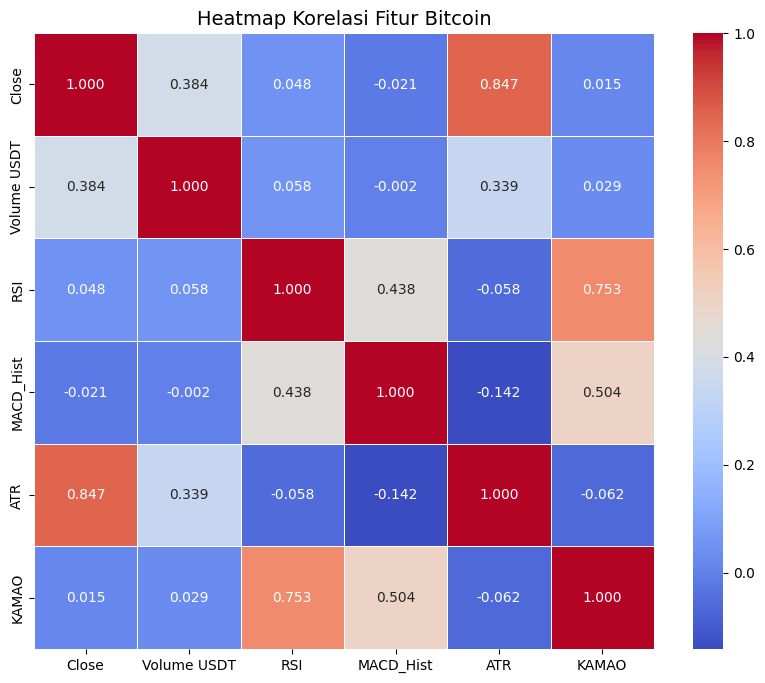

In [3]:
features = ['Close', 'Volume USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO']
df_selected = df[features]

# Visualisasi heatmap korelasi
plt.figure(figsize=(10, 8))
sns.heatmap(df_selected.corr(), annot=True, cmap='coolwarm', fmt=".3f", linewidths=0.5)
plt.title('Heatmap Korelasi Fitur Bitcoin', fontsize=14)
plt.show()

## 1.4 Analisis Dekomposisi

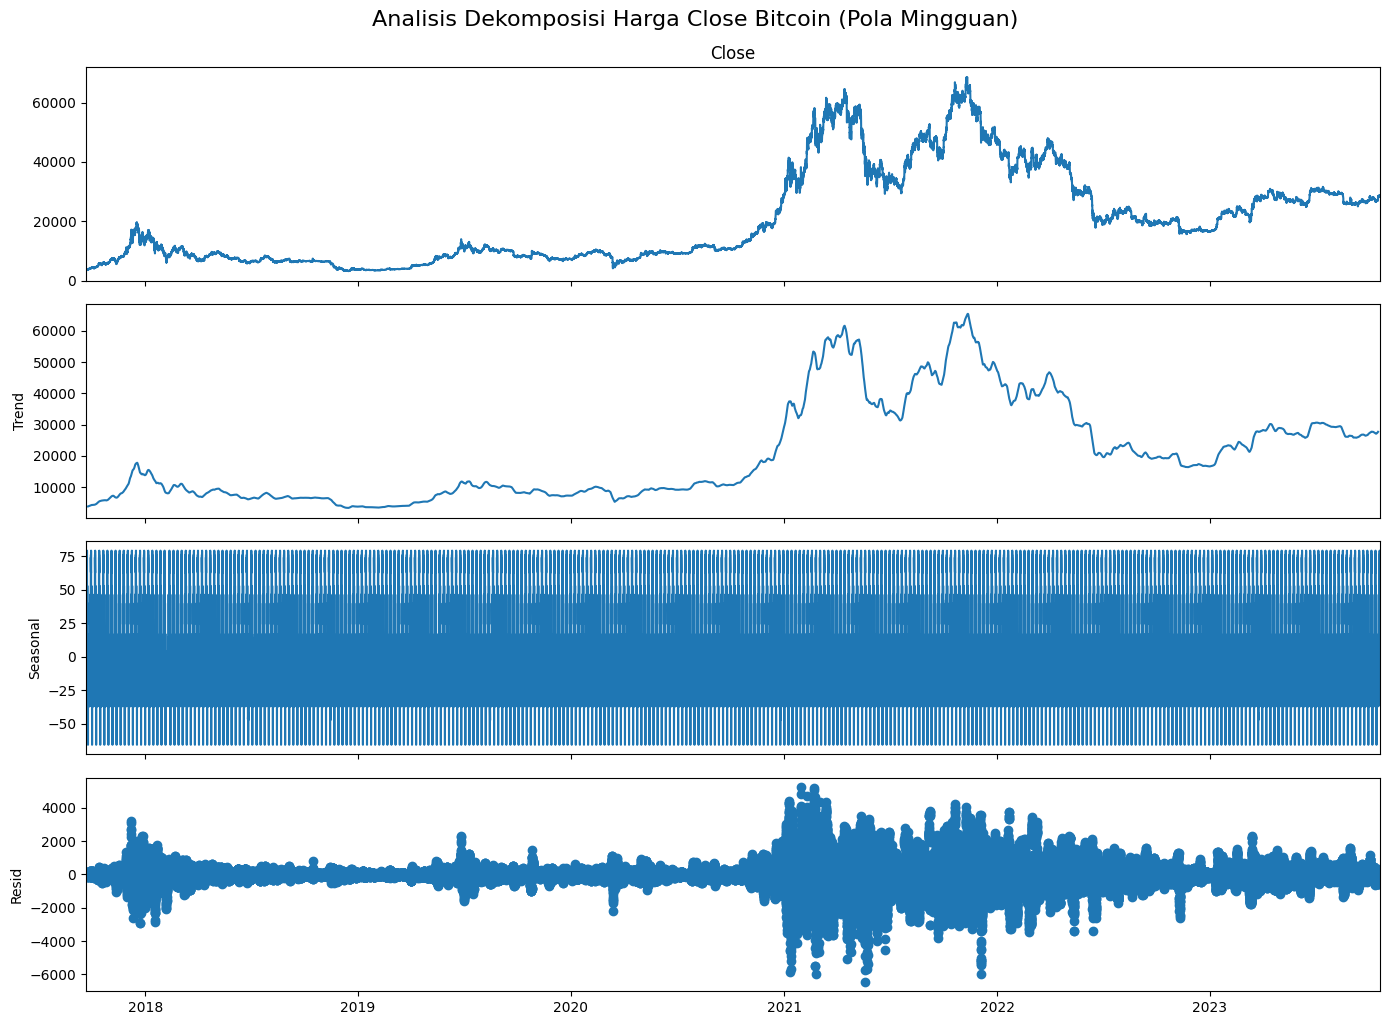

In [4]:
decompose_result = seasonal_decompose(df_selected['Close'], model='additive', period=168) # periode 168 (1 minggu) karena data bersifat per jam

# mengatur ukuran plot
plt.rcParams.update({'figure.figsize': (14,10)})
fig = decompose_result.plot()
plt.suptitle('Analisis Dekomposisi Harga Close Bitcoin (Pola Mingguan)', fontsize=16, y=1.02)
plt.show()

## 1.5 Uji ACF & PACF

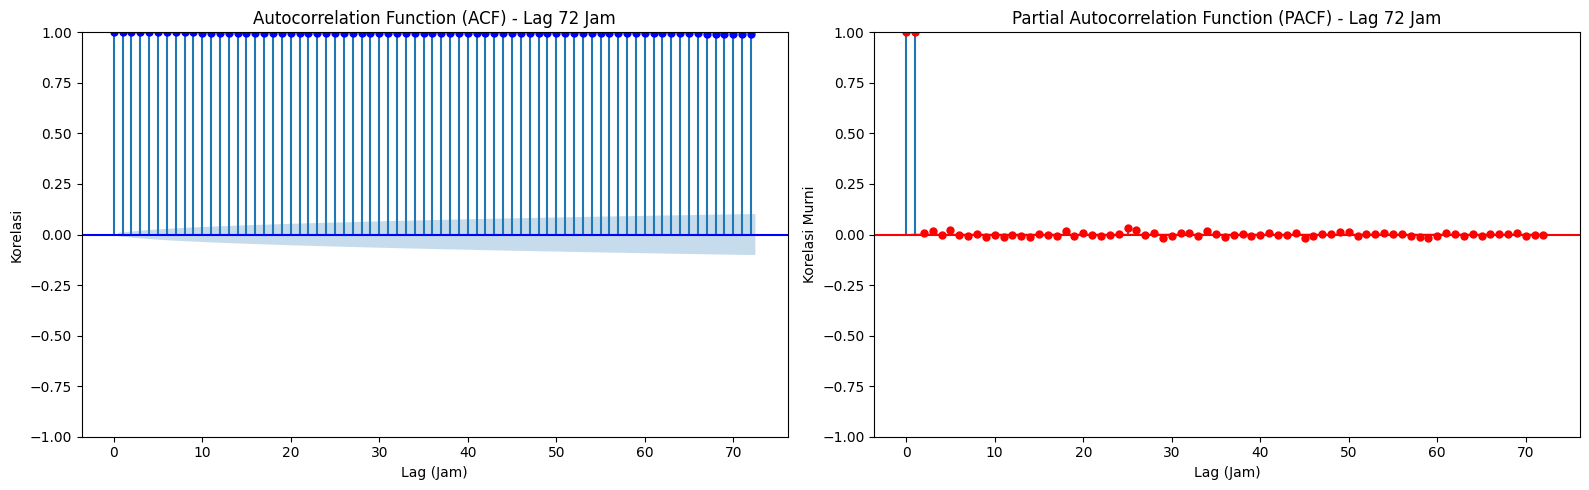

In [5]:
plt.rcParams.update({'figure.figsize': (16, 5)})

fig, axes = plt.subplots(1, 2)

# Plot ACF (Korelasi total: efek langsung & efek berantai)
plot_acf(df_selected['Close'], lags=72, ax=axes[0], color='blue')
axes[0].set_title('Autocorrelation Function (ACF) - Lag 72 Jam')
axes[0].set_xlabel('Lag (Jam)')
axes[0].set_ylabel('Korelasi')

# Plot PACF (Korelasi murni: efek langsung dari jam tersebut saja)
plot_pacf(df_selected['Close'], lags=72, ax=axes[1], color='red')
axes[1].set_title('Partial Autocorrelation Function (PACF) - Lag 72 Jam')
axes[1].set_xlabel('Lag (Jam)')
axes[1].set_ylabel('Korelasi Murni')

plt.tight_layout()
plt.show()

# 2. Preprocessing & Data Pipeline

## 2.1 Feature Engineering

In [6]:
# Mneghitung nilai rata-rata (Mean) dan Standar Deviasi (Std) pergerakan harga dalam 24 jam terakhir
df_selected['Close_Roll_Mean_24'] = df_selected['Close'].rolling(window=24).mean()
df_selected['Close_Roll_Std_24'] = df_selected['Close'].rolling(window=24).std()

# Karena menggunakan metode 'rolling' yang mana membutuhkan 24 jam pertama untuk menghitung data maka 23 baris pertamanya akan bernilai NaN. (harus dibuang)
df_selected.dropna(inplace=True)

print("Fitur saat ini: ", df_selected.columns.tolist())

Fitur saat ini:  ['Close', 'Volume USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO', 'Close_Roll_Mean_24', 'Close_Roll_Std_24']


## 1.7 Data Splitting

In [7]:
from sklearn.preprocessing import MinMaxScaler

# Membagi data (70% Train, 15% Validation, 15% Test)
n = len(df_selected)
train_df = df_selected[0: int(n*0.7)]
val_df = df_selected[int(n*0.7) : int(n*0.85)]
test_df = df_selected[int(n*0.85) :]

columns = df_selected.columns
target_col_index = columns.get_loc("Close")
scaler = MinMaxScaler()

# supaya data tidak leakage (fit Scaler hanya pada data training)
train_scaled = scaler.fit_transform(train_df)

val_scaled = scaler.transform(val_df)
test_scaled = scaler.transform(test_df)

print(f"Jumlah data - Train: {len(train_scaled)}")
print(f"Jumlah data - Val: {len(val_scaled)}")
print(f"Jumlah data - Test: {len(test_scaled)}")

Jumlah data - Train: 37188
Jumlah data - Val: 7969
Jumlah data - Test: 7970


## 2.2 Membuat tf.data.Dataset Pipeline

In [8]:
import tensorflow as tf
import numpy as np

window_size = 24 # Input : data 24 jam kebelakang berdasarkan analisis PACF
horizon = 24 # Output : memprediksi 24 langkah (jam) ke depan

# Fungsi untuk memotong data menjadi sequence [X] dan target 24 langkah [y]
def multi_step_dataset(data, window_size, horizon, target_index):
  X, y = [], []
  for i in range(len(data) - window_size - horizon + 1):
    X.append(data[i : (i + window_size), :])
    y.append(data[(i + window_size) : (i + window_size + horizon), target_index])
  return np.array(X), np.array(y)

# membuat array sekuensial
X_train, y_train = multi_step_dataset(train_scaled, window_size, horizon, target_col_index)
X_val, y_val = multi_step_dataset(val_scaled, window_size, horizon, target_col_index)
X_test, y_test = multi_step_dataset(test_scaled, window_size, horizon, target_col_index)

# mengkonversi array ke tf.data.Dataset pipeline
batch_size = 64
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).batch(batch_size).prefetch(tf.data.AUTOTUNE)
val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(batch_size).prefetch(tf.data.AUTOTUNE)
test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(batch_size).prefetch(tf.data.AUTOTUNE)

print("Bentuk Input Model (X_train):", X_train.shape)
print("Bentuk Output Model (y_train):", y_train.shape)

2026-05-16 08:20:56.116672: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778919656.674847      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778919656.779765      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778919657.843001      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778919657.843041      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778919657.843044      57 computation_placer.cc:177] computation placer alr

Bentuk Input Model (X_train): (37141, 24, 8)
Bentuk Output Model (y_train): (37141, 24)


I0000 00:00:1778919695.825055      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1778919695.831027      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


# 3. Arsitektur Model & Custom Layer

## 3.1 Custom Layers

In [9]:
import tensorflow as tf
from tensorflow.keras.layers import Layer, Input, LSTM, Flatten
from tensorflow.keras.models import Model

# Membuat Layer Dense dari Nol
class CustomDense(Layer):
  def __init__(self, units, **kwargs):
    super(CustomDense, self).__init__(**kwargs)
    self.units = units

  def build(self, input_shape):
    self.w = self.add_weight(shape=(input_shape[-1], self.units),
                             initializer='glorot_uniform', trainable=True, name='kernel')
    self.b = self.add_weight(shape=(self.units,), initializer='zeros', trainable=True, name='bias')
    super(CustomDense, self).build(input_shape)

  def call(self, inputs):
    return tf.matmul(inputs, self.w) + self.b

# Membuat layer Multi-Head Attention dari Nol
class CustomMultiHeadAttention(Layer):
  def __init__(self, num_heads, head_dim, **kwargs):
    super(CustomMultiHeadAttention, self).__init__(**kwargs)
    self.num_heads = num_heads
    self.head_dim = head_dim
    self.d_model = num_heads * head_dim

  def build(self, input_shape):
    # Layer transformasi untuk Query (Q), Key (K), dan Value (V)
    self.wq = tf.keras.layers.Dense(self.d_model)
    self.wk = tf.keras.layers.Dense(self.d_model)
    self.wv = tf.keras.layers.Dense(self.d_model)
    self.dense = tf.keras.layers.Dense(input_shape[-1])
    super(CustomMultiHeadAttention, self).build(input_shape)

  def split_heads(self, x, batch_size):
    x = tf.reshape(x, (batch_size, -1, self.num_heads, self.head_dim))
    return tf.transpose(x, perm=[0, 2, 1, 3])

  def call(self, q, k, v):
    batch_size = tf.shape(q)[0]

    seq_len = q.shape[1]

    q_proj, k_proj, v_proj = self.wq(q), self.wk(k), self.wv(v)
    q_proj = self.split_heads(q_proj, batch_size)
    k_proj = self.split_heads(k_proj, batch_size)
    v_proj = self.split_heads(v_proj, batch_size)


    matmul_qk = tf.matmul(q_proj, k_proj, transpose_b=True)
    dk = tf.cast(tf.shape(k_proj)[-1], tf.float32)
    scaled_attention_logits = matmul_qk / tf.math.sqrt(dk)

    attention_weights = tf.nn.softmax(scaled_attention_logits, axis=-1)
    output = tf.matmul(attention_weights, v_proj)

    output = tf.transpose(output, perm=[0, 2, 1, 3])
    concat_attention = tf.reshape(output, (batch_size, -1, self.d_model))
    final_output = self.dense(concat_attention)

    final_output.set_shape((None, seq_len, final_output.shape[-1]))
    return final_output

# Custom Layer Activation
class CustomLeakyReLU(Layer):
  def __init__(self, alpha=0.1, **kwargs):
    super(CustomLeakyReLU, self).__init__(**kwargs)
    self.alpha = alpha

  def call(self, inputs):
    return tf.maximum(self.alpha * inputs, inputs)

## 3.2 Model 1 - Baseline LSTM dengan Custom Layers

In [10]:
def baseline_model(window_size, num_features, horizon):
  inputs = Input(shape=(window_size, num_features))

  # layer LSTM
  x = LSTM(64, return_sequences=True)(inputs)

  x = CustomMultiHeadAttention(num_heads=2, head_dim=32)(x, x, x)
  x = Flatten()(x)
  x = CustomLeakyReLU(alpha=0.1)(x)

  outputs = CustomDense(units=horizon)(x)

  model = Model(inputs=inputs, outputs=outputs, name="model_baseline_LSTM")
  return model

num_features = X_train.shape[2]

# Bangun model
model_baseline_lstm = baseline_model(window_size=24, num_features=num_features, horizon=24)

# tampilkan rangkuman arsitektur model
model_baseline_lstm.summary()

Model: "model_baseline_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 24, 8)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 24, 64)    │     18,688 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ custom_multi_head_… │ (None, 24, 64)    │     16,640 │ lstm[0][0],       │
│ (CustomMultiHeadAt… │                   │            │ lstm[0][0],       │
│                     │                   │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 1536)      │          0 │ custom_multi_hea… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ custom_leaky_re_lu  │ (None, 1536)      │          0 │ flatten[0][0]     │
│ (CustomLeakyReLU)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ custom_dense        │ (None, 24)        │     36,888 │ custom_leaky_re_… │
│ (CustomDense)       │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 72,216 (282.09 KB)

 Trainable params: 72,216 (282.09 KB)

 Non-trainable params: 0 (0.00 B)

## 3.3 Model 2 - Seq2Seq LSTM dengan Subclassing

In [11]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import LSTM

class Seq2SeqTeacherForcing(Model):
    def __init__(self, units, horizon, **kwargs):
        super(Seq2SeqTeacherForcing, self).__init__(**kwargs)
        self.horizon = horizon
        self.units = units
        
        self.encoder_lstm = LSTM(units, return_sequences=True, return_state=True)
        self.attention = CustomMultiHeadAttention(num_heads=2, head_dim=32)
        self.decoder_lstm = LSTM(units, return_sequences=True, return_state=True)
        self.custom_dense = CustomDense(units=1) 

    def call(self, inputs, targets=None, training=False):
        enc_outputs, state_h, state_c = self.encoder_lstm(inputs)
        
        dec_input = tf.reshape(inputs[:, -1, 0], [-1, 1, 1]) #tf.reshape absolut untuk inisialisasi awal
        
        predictions = []
        
        for t in range(self.horizon):
            dec_outputs, state_h, state_c = self.decoder_lstm(
                dec_input, initial_state=[state_h, state_c]
            )
            
            context_vector = self.attention(dec_outputs, enc_outputs, enc_outputs)
            combined = tf.concat([dec_outputs, context_vector], axis=-1)
            
            pred = self.custom_dense(combined) 
            
            # Simpan tebakan dalam bentuk 2D untuk ditumpuk nanti
            pred_flat = tf.reshape(pred, [-1, 1])
            predictions.append(pred_flat)
            
            # Ini untuk Penentuan input untuk step berikutnya 
            if training and targets is not None:
                # Fase Training (TEACHER FORCING)
                dec_input = tf.reshape(targets[:, t], [-1, 1, 1])
            else:
                # Fase Validasi (AUTOREGRESSIVE)
                dec_input = tf.reshape(pred, [-1, 1, 1]) #tf.reshape absolut agar kebal dari error 4D dimensi
                
        predictions = tf.stack(predictions, axis=1)
        predictions = tf.squeeze(predictions, axis=-1) 
        
        return predictions

# Instansiasi ulang model dengan kapasitas 128
model_seq2seq_lstm = Seq2SeqTeacherForcing(units=128, horizon=24, name="model_seq2seq_LSTM")

# Build arsitektur dengan data dummy
dummy_inputs = tf.random.normal((1, window_size, num_features))
dummy_targets = tf.random.normal((1, horizon))
_ = model_seq2seq_lstm(dummy_inputs, targets=dummy_targets, training=True)

model_seq2seq_lstm.summary()

I0000 00:00:1778919715.052561     132 cuda_dnn.cc:529] Loaded cuDNN version 91002


Model: "model_seq2seq_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ ((1, 24, 128), (1,     │        70,144 │
│                                 │ 128), (1, 128))        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_multi_head_attention_1   │ ?                      │        33,088 │
│ (CustomMultiHeadAttention)      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ((1, 1, 128), (1,      │        66,560 │
│                                 │ 128), (1, 128))        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_dense_1 (CustomDense)    │ ?                      │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 170,049 (664.25 KB)

 Trainable params: 170,049 (664.25 KB)

 Non-trainable params: 0 (0.00 B)

# 4. Custom Training Loop & Evaluasi

## 4.1 Custom Loss & Callbacks

In [12]:
import tensorflow as tf

# Custom Loss : MAE
def custom_weighted_mae(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    horizon = tf.shape(y_true)[1]
    step_indices = tf.cast(tf.range(horizon), tf.float32)
    weights = 1.0 + (step_indices * 0.05)
    weights = tf.reshape(weights, (1, -1))

    mae_base = tf.abs(y_true - y_pred)
    weighted_mae = mae_base * weights
    return tf.reduce_mean(weighted_mae)

# Custom callbacks (Early Stopping & Reduce LR)
class CustomTrainingManager:
  def __init__(self, patience=5, reduce_lr_patience=3, factor=0.5, min_lr=1e-5, initial_lr=0.001):
    self.patience = patience
    self.reduce_lr_patience = reduce_lr_patience
    self.factor = factor
    self.min_lr = min_lr
    self.best_loss = float('inf')
    self.wait = 0
    self.lr_wait = 0
    self.stop_training = False
    self.current_lr = initial_lr
    self.best_weights = None # Menyimpan memori bobot terbaik

  def check(self, val_loss, optimizer, model):
    if val_loss < self.best_loss:
      self.best_loss = val_loss
      self.wait = 0
      self.lr_wait = 0
      # Simpan bobot saat model berada di performa puncak
      self.best_weights = model.get_weights()
    else:
      self.wait += 1
      self.lr_wait += 1

    if self.lr_wait >= self.reduce_lr_patience:
      new_lr = max(self.current_lr * self.factor, self.min_lr)
      optimizer.learning_rate.assign(new_lr)
      print(f" -> [Info] Val loss stagnan. Learning Rate diturunkan menjadi: {new_lr:.6f}")
      self.current_lr = new_lr
      self.lr_wait = 0

    if self.wait >= self.patience:
      print(f" -> [Info] Early Stopping terpicu! Mengembalikan bobot terbaik model (Loss: {self.best_loss:.4f})")
      self.stop_training = True
      # Kembalikan model ke bobot terbaiknya sebelum berhenti
      if self.best_weights is not None:
        model.set_weights(self.best_weights)

## 4.2 Custom Training Loop dengan tf.GradientTape

In [13]:
import time

def train_custom_model(model, train_dataset, val_dataset, epochs, is_seq2seq=False):
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
    manager = CustomTrainingManager(patience=12, reduce_lr_patience=4)
    
    print(f"Memulai Training untuk model: {model.name}")
    print("-" * 50)
    
    # Mengkompilasi Ke Graph C++ agar lebih cepat saat proses training
    @tf.function
    def train_step(x, y):
        with tf.GradientTape() as tape:
            if is_seq2seq:
                predictions = model(x, targets=y, training=True)
            else:
                predictions = model(x, training=True)
            loss = custom_weighted_mae(y, predictions)
        grads = tape.gradient(loss, model.trainable_weights)
        optimizer.apply_gradients(zip(grads, model.trainable_weights))
        return loss

    @tf.function
    def val_step(x, y):
        if is_seq2seq:
            val_predictions = model(x, targets=None, training=False)
        else:
            val_predictions = model(x, training=False)
        return custom_weighted_mae(y, val_predictions)
    
    for epoch in range(epochs):
        start_time = time.time()
        train_loss_tracker = tf.keras.metrics.Mean()
        
        # Fase Training
        for x_batch_train, y_batch_train in train_dataset:
            loss_value = train_step(x_batch_train, y_batch_train)
            train_loss_tracker.update_state(loss_value)
            
        # Fase Validaation
        val_loss_tracker = tf.keras.metrics.Mean()
        for x_batch_val, y_batch_val in val_dataset:
            val_loss = val_step(x_batch_val, y_batch_val)
            val_loss_tracker.update_state(val_loss)
            
        epoch_time = time.time() - start_time
        print(f"Epoch {epoch+1:02d}/{epochs} | Waktu: {epoch_time:.0f}s | Train Loss: {train_loss_tracker.result():.4f} | Val Loss: {val_loss_tracker.result():.4f}")
        
        # Masukkan model ke dalam manager agar bobotnya bisa dievaluasi & disimpan
        manager.check(val_loss_tracker.result(), optimizer, model)
        if manager.stop_training:
            break
            
    print("Training Selesai!\n")
    return model

# reset model seq2seq agar belajar dari awal
model_seq2seq_lstm = Seq2SeqTeacherForcing(units=128, horizon=24, name="model_seq2seq_LSTM")
dummy_inputs = tf.random.normal((1, window_size, num_features))
dummy_targets = tf.random.normal((1, horizon))
_ = model_seq2seq_lstm(dummy_inputs, targets=dummy_targets, training=True)

epochs_to_run = 100 

# Menjalalankan Training untuk Model LSTM
print("--- TRAINING MODEL 1: BASELINE LSTM ---")
trained_baseline = train_custom_model(model_baseline_lstm, train_dataset, val_dataset, epochs_to_run, is_seq2seq=False)

# Menjalankan Training untuk Model Seq2Seq dengan Graph Mode
print("\n--- TRAINING MODEL 2: SEQ2SEQ LSTM ---")
trained_seq2seq = train_custom_model(model_seq2seq_lstm, train_dataset, val_dataset, epochs_to_run, is_seq2seq=True)

--- TRAINING MODEL 1: BASELINE LSTM ---
Memulai Training untuk model: model_baseline_LSTM
--------------------------------------------------
Epoch 01/100 | Waktu: 9s | Train Loss: 0.0259 | Val Loss: 0.3716
Epoch 02/100 | Waktu: 4s | Train Loss: 0.0448 | Val Loss: 0.3663
Epoch 03/100 | Waktu: 4s | Train Loss: 0.0452 | Val Loss: 0.3368
Epoch 04/100 | Waktu: 4s | Train Loss: 0.0403 | Val Loss: 0.2976
Epoch 05/100 | Waktu: 4s | Train Loss: 0.0399 | Val Loss: 0.3357
Epoch 06/100 | Waktu: 4s | Train Loss: 0.0404 | Val Loss: 0.3419
Epoch 07/100 | Waktu: 4s | Train Loss: 0.0390 | Val Loss: 0.2733
Epoch 08/100 | Waktu: 4s | Train Loss: 0.0392 | Val Loss: 0.3315
Epoch 09/100 | Waktu: 4s | Train Loss: 0.0352 | Val Loss: 0.2758
Epoch 10/100 | Waktu: 4s | Train Loss: 0.0369 | Val Loss: 0.2902
Epoch 11/100 | Waktu: 4s | Train Loss: 0.0359 | Val Loss: 0.2936
 -> [Info] Val loss stagnan. Learning Rate diturunkan menjadi: 0.000500
Epoch 12/100 | Waktu: 4s | Train Loss: 0.0421 | Val Loss: 0.2267
Epoch 1

## 4.3 Inference & Perhitungan MAE

In [14]:
from sklearn.metrics import mean_absolute_error
import numpy as np
import tensorflow as tf

print("Melakukan Inference pada Model Baseline...")
baseline_preds_list = []
for x_batch, _ in test_dataset:
    preds = model_baseline_lstm(x_batch, training=False)
    baseline_preds_list.append(preds)
baseline_predictions = tf.concat(baseline_preds_list, axis=0).numpy()

print("Melakukan Inference Eksternal pada Model Seq2Seq (Autoregressive)...")
def autoregressive_inference(model, inputs, horizon):
    enc_outputs, state_h, state_c = model.encoder_lstm(inputs)
    
    # Memastikan input awal benar-benar 3D: (batch_size, 1, 1)
    dec_input = tf.reshape(inputs[:, -1, 0], [-1, 1, 1])
    
    predictions = []
    
    for t in range(horizon):
        dec_outputs, state_h, state_c = model.decoder_lstm(dec_input, initial_state=[state_h, state_c])
        context_vector = model.attention(dec_outputs, enc_outputs, enc_outputs)
        combined = tf.concat([dec_outputs, context_vector], axis=-1)
        
        pred = model.custom_dense(combined)
        
        # Simpan prediksi dalam bentuk 2D: (batch_size, 1)
        pred_flat = tf.reshape(pred, [-1, 1])
        predictions.append(pred_flat)
        
        # Memaksa dec_input menjadi 3D (batch_size, 1, 1)
        dec_input = tf.reshape(pred, [-1, 1, 1])
        
    preds_stacked = tf.stack(predictions, axis=1)
    return tf.squeeze(preds_stacked, axis=-1)

seq2seq_preds_list = []
for x_batch, _ in test_dataset:
    preds = autoregressive_inference(model_seq2seq_lstm, x_batch, horizon=24)
    seq2seq_preds_list.append(preds)
    
seq2seq_predictions = tf.concat(seq2seq_preds_list, axis=0).numpy()

# Perhitungan MAE
mae_baseline_scaled = mean_absolute_error(y_test.flatten(), baseline_predictions.flatten())
mae_seq2seq_scaled = mean_absolute_error(y_test.flatten(), seq2seq_predictions.flatten())

print("-" * 30)
print("Evaluasi MAE (Skala 0-1):")
print(f"MAE Baseline LSTM : {mae_baseline_scaled:.5f}")
print(f"MAE Seq2Seq LSTM  : {mae_seq2seq_scaled:.5f}")
print("-" * 30)

# Inverse Scaling
num_features_for_scaler = scaler.n_features_in_ 

def inverse_transform_predictions(predictions, scaler, target_index, num_features):
    pred_flat = predictions.flatten()
    dummy_array = np.zeros((len(pred_flat), num_features))
    dummy_array[:, target_index] = pred_flat
    inverse_scaled = scaler.inverse_transform(dummy_array)[:, target_index]
    return inverse_scaled.reshape(predictions.shape)

print("Melakukan Inverse Scaling...")
baseline_preds_inv = inverse_transform_predictions(baseline_predictions, scaler, target_col_index, num_features_for_scaler)
seq2seq_preds_inv = inverse_transform_predictions(seq2seq_predictions, scaler, target_col_index, num_features_for_scaler)
y_test_inv = inverse_transform_predictions(y_test, scaler, target_col_index, num_features_for_scaler)

print("Inference dan Inverse Scaling Selesai!")

Melakukan Inference pada Model Baseline...
Melakukan Inference Eksternal pada Model Seq2Seq (Autoregressive)...
------------------------------
Evaluasi MAE (Skala 0-1):
MAE Baseline LSTM : 0.01149
MAE Seq2Seq LSTM  : 0.02547
------------------------------
Melakukan Inverse Scaling...
Inference dan Inverse Scaling Selesai!


## 4.4 Visual hasil (line Chart & Tabel)

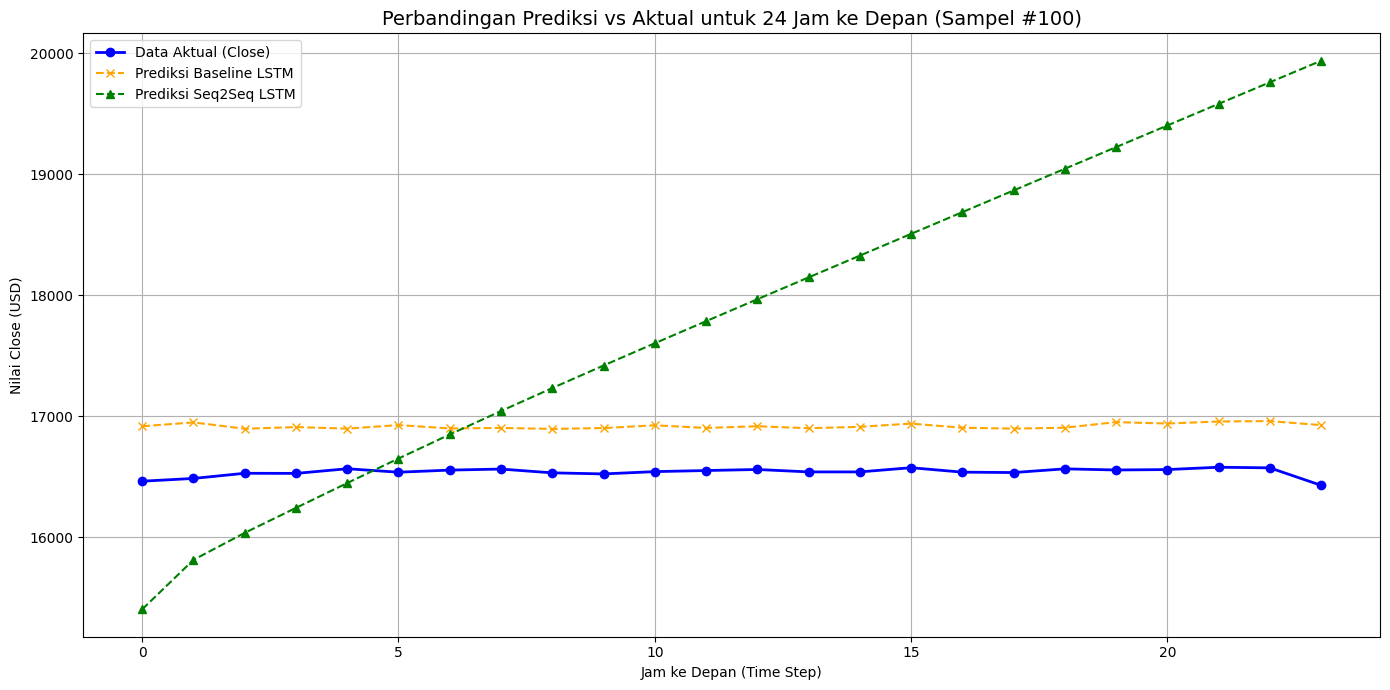


Tabel Perbandingan Data Aktual vs Hasil Prediksi (Model Seq2Seq):
--------------------------------------------------------------------------------


,Jam ke,Data Aktual,Prediksi Seq2Seq,Selisih
0,1,16462.67,15403.67,1059.00
1,2,16485.56,15812.46,673.10
2,3,16528.20,16035.60,492.60
3,4,16527.22,16242.13,285.09
4,5,16565.70,16447.35,118.35
5,6,16537.01,16650.20,113.19
6,7,16554.51,16848.84,294.33
7,8,16562.98,17042.79,479.81
8,9,16531.75,17232.54,700.79
9,10,16522.92,17418.99,896.07


In [15]:
from IPython.display import display

sample_idx = 100

# Ekstrak data aktual
actual = y_test_inv[sample_idx]
pred_baseline = baseline_preds_inv[sample_idx]
pred_seq2seq = pred_seq2seq = seq2seq_preds_inv[sample_idx]

# 1. Visualisasi Line Chart
plt.figure(figsize=(14, 7))
plt.plot(actual, label='Data Aktual (Close)', marker='o', color='blue', linewidth=2)
plt.plot(pred_baseline, label='Prediksi Baseline LSTM', marker='x', linestyle='--', color='orange')
plt.plot(pred_seq2seq, label='Prediksi Seq2Seq LSTM', marker='^', linestyle='--', color='green')

plt.title(f'Perbandingan Prediksi vs Aktual untuk 24 Jam ke Depan (Sampel #{sample_idx})', fontsize=14)
plt.xlabel('Jam ke Depan (Time Step)')
plt.ylabel('Nilai Close (USD)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. Visualisasi Tabel (DataFrame)
# Membuat DataFrame untuk tabel perbandingan
df_comparison = pd.DataFrame({
    'Jam ke': range(1, 25),
    'Data Aktual': actual,
    'Prediksi Seq2Seq': pred_seq2seq
})

# Menambahkan kolom selisih absolut 
df_comparison['Selisih'] = np.abs(df_comparison['Data Aktual'] - df_comparison['Prediksi Seq2Seq'])

print("\nTabel Perbandingan Data Aktual vs Hasil Prediksi (Model Seq2Seq):")
print("-" * 80)
# Tampilkan tabel yang lebih rapi
display(df_comparison.round(2))

# 5. Simpan Model

In [16]:
# Menyimpan model ke format .keras 
print("Menyimpan model ke dalam format .keras...")

# 1. Dokumen Model 
model_baseline_lstm.save('model_baseline_LSTM.keras')
print("- model_baseline_LSTM.keras berhasil disimpan.")

model_seq2seq_lstm.save('model_seq2seq_LSTM.keras')
print("- model_seq2seq_LSTM.keras berhasil disimpan.")

# 2. Dokumen Model Opsional (salinan dari model Seq2Seq terbaik)
model_seq2seq_lstm.save('best_model_seq2seq_LSTM.keras')
print("- best_model_seq2seq_LSTM.keras berhasil disimpan.")

Menyimpan model ke dalam format .keras...
- model_baseline_LSTM.keras berhasil disimpan.
- model_seq2seq_LSTM.keras berhasil disimpan.
- best_model_seq2seq_LSTM.keras berhasil disimpan.


In [17]:
# Membuat file requirements.txt yang berisi daftar library environment saat ini
!pip freeze > requirements.txt
print("File requirements.txt berhasil dibuat.")

File requirements.txt berhasil dibuat.
